# 08. Quimiocinas CXCL9/10/11

CXCL9, CXCL10 y CXCL11 se producen en respuesta al interferón gamma y atraen a los linfocitos T con el receptor CXCR3. Se calcula, por muestra y tipo celular, el porcentaje de células con al menos una molécula de alguna de las tres. Se probó LIANA para estimar comunicación entre tipos celulares, pero su filtro de expresión mínima eliminaba las tres quimiocinas.

La baja detección es un límite conocido de la técnica: la digestión enzimática de la biopsia estresa y pierde células, y 10x captura solo una fracción de las moléculas de cada célula, así que los genes poco expresados aparecen en cero aunque estén.

In [1]:
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import mannwhitneyu

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

adata = sc.read_h5ad(DIR_PROCESADOS / "03_anotado.h5ad")

In [2]:
import math

import seaborn as sns

COLORES = {"Sano": "#7a7a7a", "NL": "#5b8db8", "LS": "#c0504d"}
ORDEN = ["Sano", "NL", "LS"]
CMAP_EXPR = LinearSegmentedColormap.from_list("expresion", ["#e6e6e6", "#c0504d", "#5c1f1d"])


def colores_categoria(adata, columna, paleta):
    """Guarda en adata.uns los colores de una columna categórica, en el orden de sus categorías."""
    cats = adata.obs[columna].cat.categories
    if isinstance(paleta, dict):
        adata.uns[f"{columna}_colors"] = [paleta[c] for c in cats]
    else:
        adata.uns[f"{columna}_colors"] = [mcolors.to_hex(c) for c in paleta[:len(cats)]]


def boxplot_condicion(ax, datos, y, titulo="", ylabel="", negrita=False, sin_punto=()):
    """Caja sólida por condición con un punto negro por muestra.

    sin_punto: muestras que cuentan para la caja pero cuyo punto se dibuja aparte.
    """
    sns.boxplot(data=datos, x="condicion", y=y, order=ORDEN,
                hue="condicion", hue_order=ORDEN, palette=COLORES, width=0.6,
                showfliers=False, dodge=False, linecolor="black", linewidth=1,
                medianprops={"color": "black", "linewidth": 2}, legend=False, ax=ax)
    puntos = datos[~datos["muestra"].isin(sin_punto)] if sin_punto else datos
    sns.stripplot(data=puntos, x="condicion", y=y, order=ORDEN,
                  color="black", size=4, jitter=0.05, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_title(titulo, fontsize=10, fontweight="bold" if negrita else "normal")


def rejilla_condicion(largo, panel, y, titulos, ylabel, ncols=3, resaltar=()):
    """Un boxplot por panel. titulos: {panel: texto del título}."""
    nfilas = math.ceil(len(titulos) / ncols)
    fig, axes = plt.subplots(nfilas, ncols, figsize=(3 * ncols, 3 * nfilas), squeeze=False)
    for ax, (nombre, titulo) in zip(axes.flat, titulos.items()):
        boxplot_condicion(ax, largo[largo[panel] == nombre], y, titulo,
                          negrita=nombre in resaltar)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    for ax in axes.flat[len(titulos):]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig

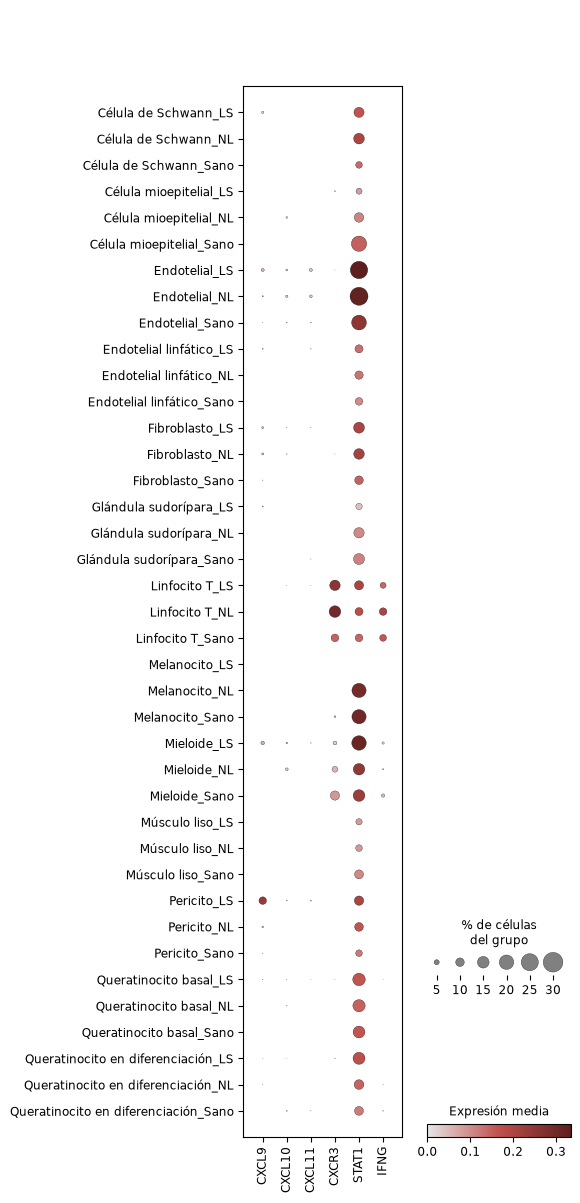

In [3]:
sc.pl.dotplot(adata, ["CXCL9", "CXCL10", "CXCL11", "CXCR3", "STAT1", "IFNG"],
              groupby=["tipo", "condicion"], cmap=CMAP_EXPR,
              size_title="% de células\ndel grupo", colorbar_title="Expresión media", show=False)
plt.savefig(DIR_FIGURAS / "dotplot_eje_CXCL_CXCR3.png", dpi=300, bbox_inches="tight")

Solo se cuentan las muestras con al menos 30 células del tipo.

In [4]:
quimiocinas = ["CXCL9", "CXCL10", "CXCL11"]
tipos = ["Endotelial", "Fibroblasto", "Mieloide", "Queratinocito basal"]

df = sc.get.obs_df(adata, keys=["tipo", "condicion", "muestra"] + quimiocinas, layer="counts")
df["CXCL_positiva"] = (df[quimiocinas] > 0).any(axis=1)

tabla = (df[df["tipo"].isin(tipos)]
         .groupby(["tipo", "condicion", "muestra"], observed=True)["CXCL_positiva"]
         .agg(n="size", positivas="sum").reset_index())
tabla["pct"] = (100 * tabla["positivas"] / tabla["n"]).round(2)
tabla = tabla[tabla["n"] >= 30]
tabla.to_csv(DIR_TABLAS / "quimiocinas_por_muestra.csv", index=False)
tabla

,tipo,condicion,muestra,n,positivas,pct
0,Endotelial,LS,486_LS,556,35,6.29
1,Endotelial,LS,BIO023_LS,361,43,11.91
2,Endotelial,LS,DER114_LS,278,2,0.72
3,Endotelial,LS,DER115_LS,431,16,3.71
4,Endotelial,LS,DER119_LS,413,10,2.42
5,Endotelial,LS,DER120_LS,160,1,0.62
6,Endotelial,NL,486_NL,55,0,0.00
7,Endotelial,NL,DER114_NL,307,2,0.65
8,Endotelial,NL,DER115_NL,394,29,7.36
9,Endotelial,NL,DER119_NL,226,8,3.54


In [5]:
filas = []
for tipo in tipos:
    d = tabla[tabla["tipo"] == tipo]
    g = {c: d.loc[d["condicion"] == c, "pct"] for c in ["Sano", "NL", "LS"]}
    fila = {"tipo": tipo, **{f"n_{c}": len(v) for c, v in g.items()}}
    for c in ["NL", "LS"]:
        if min(len(g[c]), len(g["Sano"])) >= 3:
            fila[f"p_{c}_vs_Sano"] = mannwhitneyu(g[c], g["Sano"]).pvalue
        else:
            fila[f"p_{c}_vs_Sano"] = np.nan
    filas.append(fila)

res = pd.DataFrame(filas)
res.round(3).to_csv(DIR_TABLAS / "quimiocinas_estadistica.csv", index=False)
res.round(3)

,tipo,n_Sano,n_NL,n_LS,p_NL_vs_Sano,p_LS_vs_Sano
0,Endotelial,6,5,6,0.519,0.092
1,Fibroblasto,5,4,6,0.867,0.028
2,Mieloide,0,2,3,NaN,NaN
3,Queratinocito basal,4,4,6,0.453,0.149


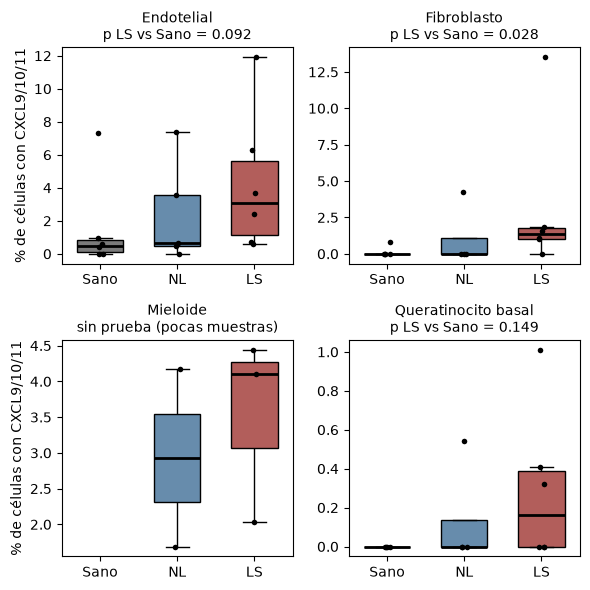

In [6]:
titulos = {}
for t in tipos:
    p = res.set_index("tipo").loc[t, "p_LS_vs_Sano"]
    titulos[t] = f"{t}\np LS vs Sano = {p:.3f}" if pd.notna(p) else f"{t}\nsin prueba (pocas muestras)"

fig = rejilla_condicion(tabla, "tipo", "pct", titulos, "% de células con CXCL9/10/11", ncols=2)
fig.savefig(DIR_FIGURAS / "quimiocinas_por_condicion.png", dpi=300, bbox_inches="tight")